In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB2
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing import image_dataset_from_directory

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import os

In [2]:
dataset_dir = "C:/Users/Afra Naima/OneDrive/Documents/SKRISPI/Dataset Skripsi/Dataset Skripsi v4/split no aug"
img_size = (260, 260)
batch_size = 32

train_ds = image_dataset_from_directory(
    os.path.join(dataset_dir, 'train'),
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True
)

val_ds = image_dataset_from_directory(
    os.path.join(dataset_dir, 'valid'),
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True
)

test_ds = image_dataset_from_directory(
    os.path.join(dataset_dir, 'test'),
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Class names:", class_names)


Found 795 files belonging to 4 classes.
Found 227 files belonging to 4 classes.
Found 113 files belonging to 4 classes.
Class names: ['A', 'B', 'Defect', 'Super']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

In [4]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.5),                    # bentuk
    layers.RandomFlip("horizontal_and_vertical"),   # orientasi
    layers.RandomZoom(0.3),                         # ukuran
    layers.RandomTranslation(0.2, 0.2),             # posisi
    layers.RandomBrightness(0.3),                   # warna
    layers.RandomContrast(0.3),                     # tekstur
], name="data_augmentation")

In [5]:
#build efficientnetb2 

base_model = EfficientNetB2(
    weights="imagenet",
    include_top=False,
    input_shape=(260, 260, 3)
)

base_model.trainable = False  # freeze awal

inputs = tf.keras.Input(shape=(260, 260, 3))

x = data_augmentation(inputs)          # AUGMENTASI MASUK MODEL
x = preprocess_input(x)                # PREPROCESS SEKALI
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb2 (Functional)     │ (None, 9, 9, 1408)     │     7,768,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1408)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1408)           │         5,632 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       360,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,135,933 (31.04 MB)

 Trainable params: 364,548 (1.39 MB)

 Non-trainable params: 7,771,385 (29.65 MB)

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/10


25/25 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.6453 - loss: 1.0085 - val_accuracy: 0.7577 - val_loss: 0.6426
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.8013 - loss: 0.5610 - val_accuracy: 0.7974 - val_loss: 0.5400
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.8151 - loss: 0.5251 - val_accuracy: 0.7621 - val_loss: 0.5364
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.8088 - loss: 0.4941 - val_accuracy: 0.7885 - val_loss: 0.4759
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.8390 - loss: 0.3966 - val_accuracy: 0.8767 - val_loss: 0.3877
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.8365 - loss: 0.4285 - val_accuracy: 0.8590 - val_loss: 0.3915
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.8579 - loss: 0.4052 - val_accuracy: 0.8811 - val_loss: 0.3347
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.8629 - loss: 0.3541 - val_accuracy: 0.8899 - val_loss: 0.3186
Epo

In [7]:
base_model.trainable = True

for layer in base_model.layers[:-70]:
    layer.trainable = False

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2
        )
    ]
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 105s 3s/step - accuracy: 0.8327 - loss: 0.4617 - val_accuracy: 0.8150 - val_loss: 0.4237 - learning_rate: 2.0000e-04
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 65s 3s/step - accuracy: 0.8654 - loss: 0.3801 - val_accuracy: 0.8899 - val_loss: 0.2907 - learning_rate: 2.0000e-04
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 67s 3s/step - accuracy: 0.9031 - loss: 0.2746 - val_accuracy: 0.8546 - val_loss: 0.3960 - learning_rate: 2.0000e-04
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - accuracy: 0.9069 - loss: 0.2495 - val_accuracy: 0.8767 - val_loss: 0.2652 - learning_rate: 2.0000e-04
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 63s 3s/step - accuracy: 0.9296 - loss: 0.2184 - val_accuracy: 0.9515 - val_loss: 0.1286 - learning_rate: 2.0000e-04
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.9396 - loss: 0.1591 - val_accuracy: 0.9163 - val_loss: 0.1939 - learning_rate: 2.0000e-04
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.9358 - loss

In [9]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9646 - loss: 0.0800
Test Accuracy: 0.9646


4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step


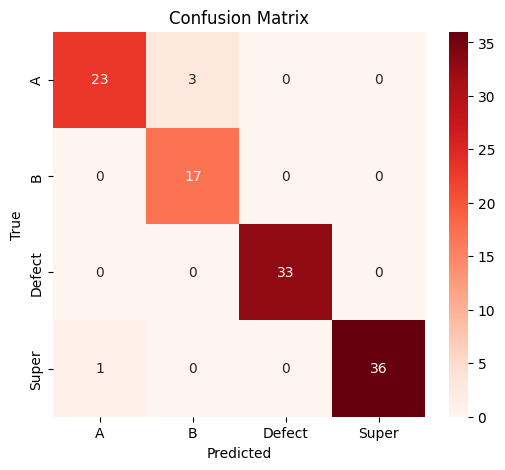


Classification Report:
              precision    recall  f1-score   support

           A       0.96      0.88      0.92        26
           B       0.85      1.00      0.92        17
      Defect       1.00      1.00      1.00        33
       Super       1.00      0.97      0.99        37

    accuracy                           0.96       113
   macro avg       0.95      0.96      0.96       113
weighted avg       0.97      0.96      0.96       113



In [10]:
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

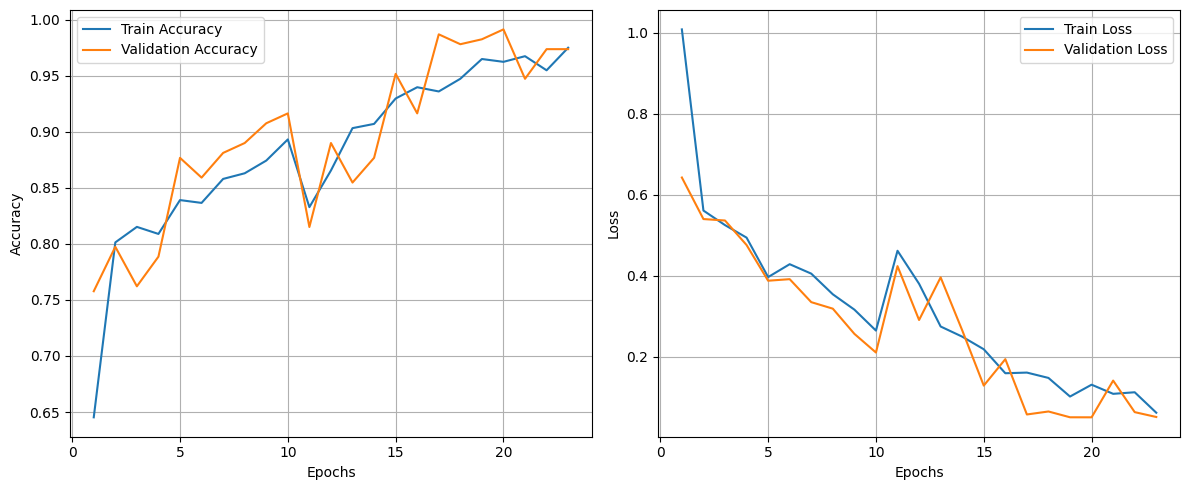

In [11]:
acc = history.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fine.history["val_accuracy"]

loss = history.history["loss"] + history_fine.history["loss"]
val_loss = history.history["val_loss"] + history_fine.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label="Train Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label="Train Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [13]:
import keras
keras.saving.save_model(model, "model_jeruk1.keras")
